Nama : Andhita Putri Aska Frisiani

NIM : 2404010002

# model klasifikasi untuk memprediksi kualitas anggur

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, warnings, io
warnings.filterwarnings('ignore')

from google.colab import files
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

unggahan = files.upload()

def baca(kata_kunci, wajib=True, **kw):
    for nama, isi in unggahan.items():
        if kata_kunci in nama.lower():
            return pd.read_csv(io.BytesIO(isi), **kw)
    if wajib:
        raise FileNotFoundError(f'File yang namanya mengandung "{kata_kunci}" belum diunggah')
    return None

train    = baca('training')
test     = baca('testing')
template = baca('hasilprediksi', wajib=False, sep=';')

if template is None:
    template = pd.DataFrame({'Id': test['Id']})

print('Data training:', train.shape)
print('Data testing :', test.shape)
print('Template     :', template.shape)
train.head()

Saving data_testing.csv to data_testing (1).csv
Saving data_training.csv to data_training (1).csv
Data training: (857, 13)
Data testing : (286, 12)
Template     : (286, 1)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


Data training berisi 857 sampel dan data testing 286 sampel. Training punya 13 kolom: 11 fitur kimiawi, target, dan Id. Testing punya kolom yang sama tanpa quality. Template berisi 286 baris, sama dengan jumlah data testing, jadi tiap Id di testing harus mendapat satu prediksi.

In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 857 entries, 0 to 856
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         857 non-null    float64
 1   volatile acidity      857 non-null    float64
 2   citric acid           857 non-null    float64
 3   residual sugar        857 non-null    float64
 4   chlorides             857 non-null    float64
 5   free sulfur dioxide   857 non-null    float64
 6   total sulfur dioxide  857 non-null    float64
 7   density               857 non-null    float64
 8   pH                    857 non-null    float64
 9   sulphates             857 non-null    float64
 10  alcohol               857 non-null    float64
 11  quality               857 non-null    int64  
 12  Id                    857 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 87.2 KB


 Semua 11 fitur bertipe angka desimal float64, sehingga tidak perlu mengubah kategori menjadi angka. Id bertipe bilangan bulat dan hanya penanda baris.

quality
3      6
4     26
5    362
6    341
7    109
8     13
Name: count, dtype: int64


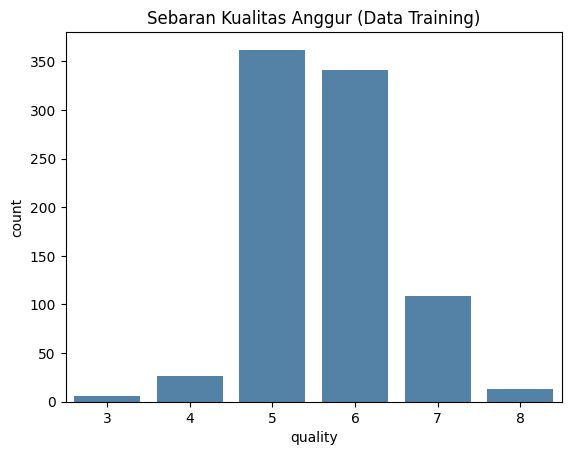

In [5]:
print(train['quality'].value_counts().sort_index())
sns.countplot(x='quality', data=train, color='steelblue')
plt.title('Sebaran Kualitas Anggur (Data Training)')
plt.show()

Kualitas anggur hanya bernilai 3 sampai 8. Sebagian besar ada di kualitas 5 (362 sampel) dan 6 (341 sampel), lalu 7 (109), 4 (26), 8 (13), dan 3 (hanya 6). Artinya data tidak seimbang: kelas di tengah mendominasi, kelas ekstrem sangat sedikit. Akibatnya model akan lebih mahir menebak kualitas 5 dan 6 daripada 3, 4, atau 8.

#pembersihan data


In [6]:
print('Nilai hilang training:', train.isnull().sum().sum())
print('Nilai hilang testing :', test.isnull().sum().sum())
print('Baris duplikat training:', train.duplicated().sum())
train.drop(columns='Id').describe().T[['min','max','mean','std']]

Nilai hilang training: 0
Nilai hilang testing : 0
Baris duplikat training: 0


,min,max,mean,std
fixed acidity,4.60000,15.6000,8.261960,1.701992
volatile acidity,0.12000,1.5800,0.529393,0.179162
citric acid,0.00000,1.0000,0.267351,0.195144
residual sugar,0.90000,15.5000,2.506184,1.293512
chlorides,0.01200,0.6110,0.086830,0.048721
free sulfur dioxide,1.00000,68.0000,15.782964,10.300402
total sulfur dioxide,6.00000,278.0000,45.978413,31.692113
density,0.99007,1.0032,0.996692,0.001901
pH,2.74000,4.0100,3.313092,0.152079
sulphates,0.39000,2.0000,0.656709,0.167364


Tidak ada nilai hilang pada data training maupun testing, dan tidak ada baris duplikat, jadi tidak diperlukan imputasi atau penghapusan data*.

residual sugar          76
chlorides               59
sulphates               31
fixed acidity           30
density                 25
total sulfur dioxide    19
free sulfur dioxide     15
pH                      14
alcohol                  9
volatile acidity         8
citric acid              1
dtype: int64


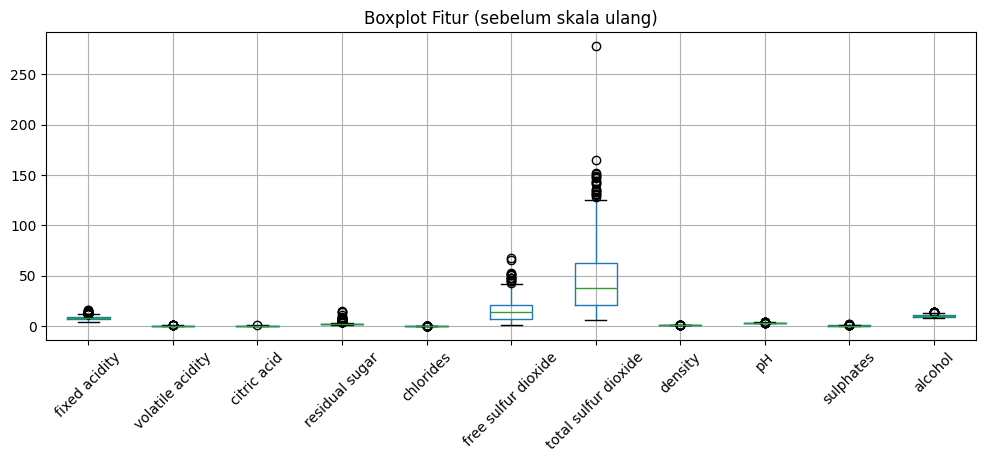

In [7]:
fitur = [c for c in train.columns if c not in ('quality','Id')]
Q1, Q3 = train[fitur].quantile(0.25), train[fitur].quantile(0.75)
IQR = Q3 - Q1
outlier = ((train[fitur] < Q1 - 1.5*IQR) | (train[fitur] > Q3 + 1.5*IQR)).sum()
print(outlier.sort_values(ascending=False))
train[fitur].boxplot(figsize=(12,4), rot=45)
plt.title('Boxplot Fitur (sebelum skala ulang)')
plt.show()

Pencilan paling banyak ada di residual sugar (76), chlorides (59), dan sulphates (31). Pencilan ini tidak dihapus karena anggur dengan kadar gula atau garam tinggi adalah hal wajar, bukan kesalahan input, dan jumlah data hanya 857 sehingga membuang baris akan menghilangkan informasi. Model berbasis pohon (Random Forest) juga tahan terhadap pencilan.


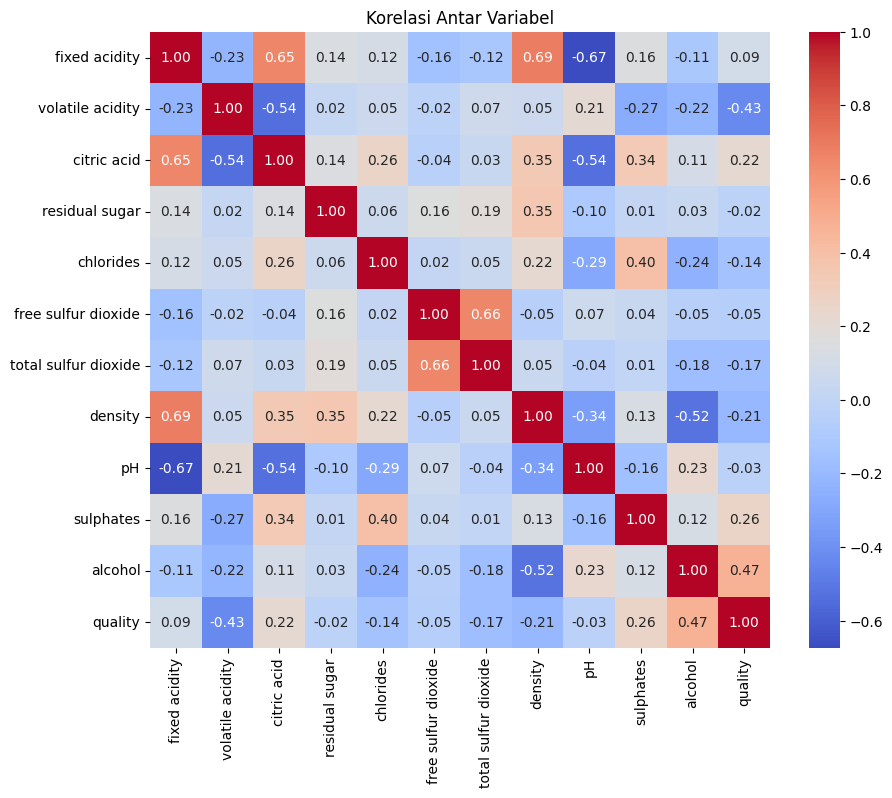

volatile acidity       -0.430059
density                -0.207903
total sulfur dioxide   -0.172737
chlorides              -0.144946
free sulfur dioxide    -0.054509
pH                     -0.033199
residual sugar         -0.020511
fixed acidity           0.092714
citric acid             0.221263
sulphates               0.260703
alcohol                 0.473555
Name: quality, dtype: float64


In [8]:
plt.figure(figsize=(10,8))
sns.heatmap(train[fitur+['quality']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi Antar Variabel')
plt.show()
print(train[fitur+['quality']].corr()['quality'].drop('quality').sort_values())

Mencari tau fitur mana yang berkaitan dengan kualitas



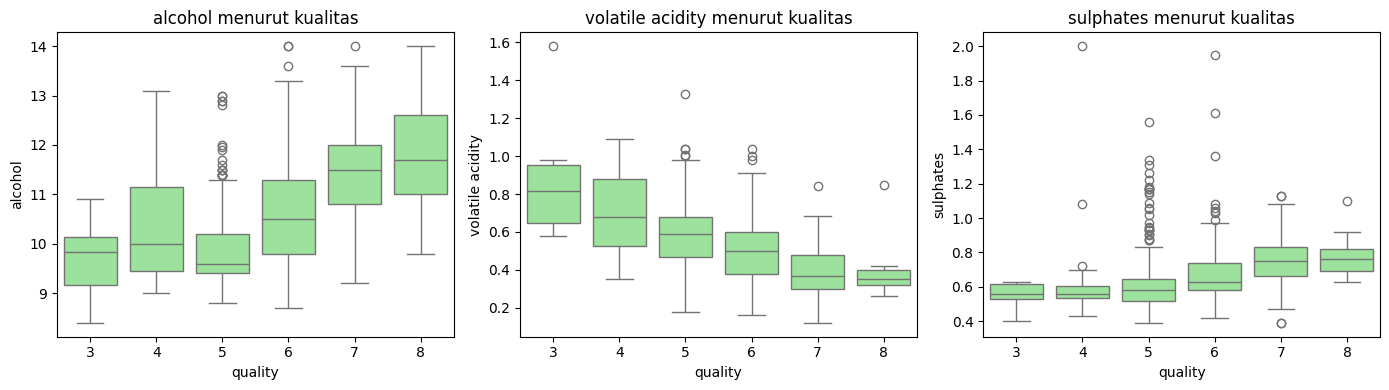

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14,4))
for a, f in zip(ax, ['alcohol','volatile acidity','sulphates']):
    sns.boxplot(x='quality', y=f, data=train, ax=a, color='lightgreen')
    a.set_title(f + ' menurut kualitas')
plt.tight_layout(); plt.show()

Median alcohol naik seiring naiknya kualitas, sedangkan volatile acidity justru turun. Pola ini konsisten dengan angka korelasi di atas.

#pembuatan model

In [10]:
X = train[fitur]
y = train['quality']
X_test = test[fitur]

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Latih:', X_tr.shape, '| Validasi:', X_val.shape)

Latih: (685, 11) | Validasi: (172, 11)


**Interpretasi:** Terbentuk 685 sampel latih dan 172 sampel validasi. Data validasi dipakai sebagai "ujian tiruan" untuk mengukur performa model pada data yang belum pernah dilihat.

              Model  Akurasi CV      Std
        Extra Trees    0.633577 0.030060
      Random Forest    0.629197 0.040614
  Gradient Boosting    0.616058 0.017639
          SVM (RBF)    0.592701 0.021356
Logistic Regression    0.585401 0.025869
         KNN (k=15)    0.548905 0.025031
      Decision Tree    0.528467 0.009901


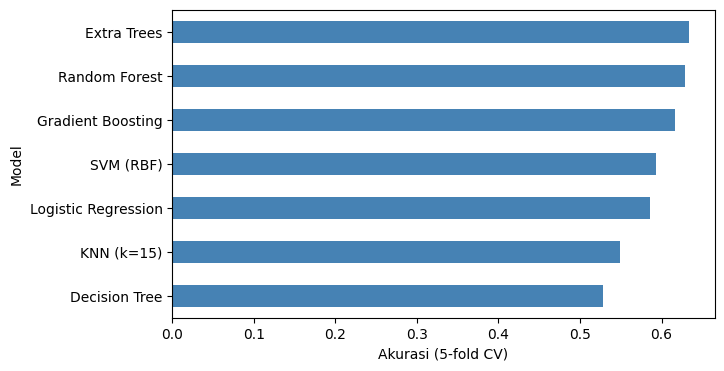

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
kandidat = {
  'Logistic Regression': Pipeline([('sc', StandardScaler()), ('m', LogisticRegression(max_iter=3000))]),
  'KNN (k=15)'         : Pipeline([('sc', StandardScaler()), ('m', KNeighborsClassifier(n_neighbors=15))]),
  'SVM (RBF)'          : Pipeline([('sc', StandardScaler()), ('m', SVC(C=3))]),
  'Decision Tree'      : DecisionTreeClassifier(max_depth=6, random_state=42),
  'Random Forest'      : RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
  'Extra Trees'        : ExtraTreesClassifier(n_estimators=300, random_state=42, n_jobs=-1),
  'Gradient Boosting'  : GradientBoostingClassifier(random_state=42),
}
hasil = []
for nama, model in kandidat.items():
    s = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='accuracy')
    hasil.append((nama, s.mean(), s.std()))
tabel = pd.DataFrame(hasil, columns=['Model','Akurasi CV','Std']).sort_values('Akurasi CV', ascending=False)
print(tabel.to_string(index=False))
tabel.plot.barh(x='Model', y='Akurasi CV', legend=False, figsize=(7,4), color='steelblue')
plt.gca().invert_yaxis(); plt.xlabel('Akurasi (5-fold CV)'); plt.show()

Berdasarkan hasil perbandingan beberapa model Machine Learning, Extra Trees memperoleh nilai akurasi Cross Validation (CV) tertinggi sebesar 0,6336 atau 63,36%, diikuti oleh Random Forest sebesar 62,92% dan Gradient Boosting sebesar 61,61%. Sementara itu, Decision Tree memperoleh akurasi terendah, yaitu 52,85%. Hasil tersebut menunjukkan bahwa Extra Trees merupakan model dengan performa terbaik dibandingkan model lainnya dalam pengujian ini. Oleh karena itu, Extra Trees dapat dipilih sebagai model terbaik untuk memprediksi kualitas wine.

In [12]:
grid = GridSearchCV(
    RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    {'max_features': ['sqrt', 0.5], 'min_samples_leaf': [1, 2], 'class_weight': [None, 'balanced_subsample']},
    cv=cv, scoring='accuracy', n_jobs=-1)
grid.fit(X_tr, y_tr)
print('Parameter terbaik:', grid.best_params_)
print('Akurasi CV terbaik:', round(grid.best_score_, 4))
model = grid.best_estimator_

Parameter terbaik: {'class_weight': 'balanced_subsample', 'max_features': 'sqrt', 'min_samples_leaf': 1}
Akurasi CV terbaik: 0.6409


Akurasi data validasi: 0.6105
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.67      0.78      0.72        73
           6       0.56      0.60      0.58        68
           7       0.50      0.27      0.35        22
           8       1.00      0.33      0.50         3

    accuracy                           0.61       172
   macro avg       0.46      0.33      0.36       172
weighted avg       0.59      0.61      0.59       172



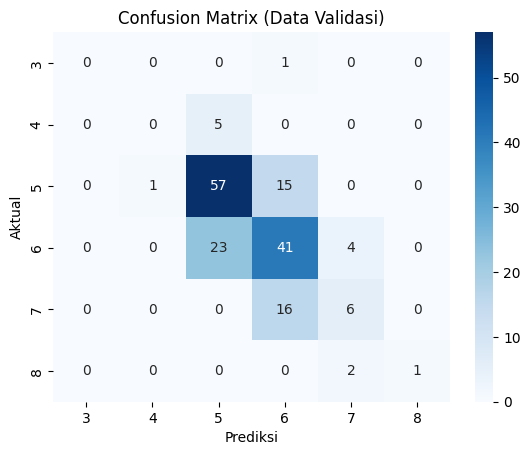

Prediksi tepat          : 0.6105
Meleset paling banyak 1 : 0.9942


In [13]:
pred = model.predict(X_val)
print('Akurasi data validasi:', round(accuracy_score(y_val, pred), 4))
print(classification_report(y_val, pred, zero_division=0))

label = sorted(y.unique())
sns.heatmap(confusion_matrix(y_val, pred, labels=label), annot=True, fmt='d', cmap='Blues',
            xticklabels=label, yticklabels=label)
plt.xlabel('Prediksi'); plt.ylabel('Aktual'); plt.title('Confusion Matrix (Data Validasi)')
plt.show()

selisih = (pred - y_val).abs()
print('Prediksi tepat          :', round((selisih == 0).mean(), 4))
print('Meleset paling banyak 1 :', round((selisih <= 1).mean(), 4))

Berdasarkan hasil evaluasi model, diperoleh nilai accuracy sebesar 61,05%, yang menunjukkan bahwa model berhasil memprediksi kelas kualitas wine dengan tepat sebesar 61,05%. Nilai precision, recall, dan F1-score tertinggi terdapat pada kelas 5, yaitu masing-masing sebesar 0,67, 0,78, dan 0,72. Sementara itu, model masih mengalami kesulitan dalam memprediksi kelas 3 dan 4 karena memiliki nilai precision, recall, dan F1-score sebesar 0. Nilai meleset paling banyak 1 sebesar 99,42% menunjukkan bahwa hampir seluruh hasil prediksi memiliki selisih maksimal satu tingkat dari nilai sebenarnya. Dengan demikian, model memiliki kemampuan prediksi yang cukup baik dalam memperkirakan kualitas wine, meskipun ketepatan prediksi untuk beberapa kelas masih perlu ditingkatkan.

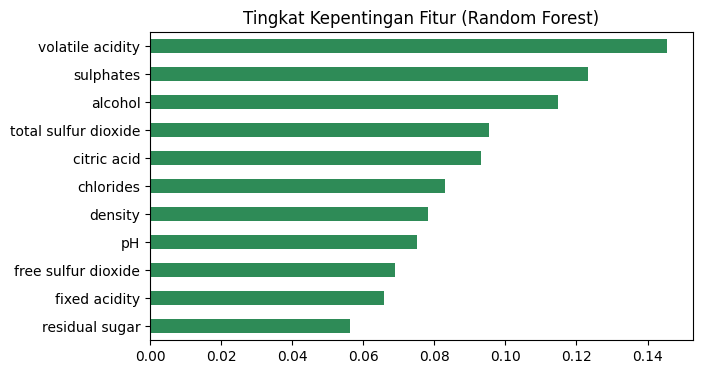

volatile acidity        0.145
sulphates               0.123
alcohol                 0.115
total sulfur dioxide    0.095
citric acid             0.093
chlorides               0.083
density                 0.078
pH                      0.075
free sulfur dioxide     0.069
fixed acidity           0.066
residual sugar          0.056
dtype: float64


In [14]:
imp = pd.Series(model.feature_importances_, index=fitur).sort_values()
imp.plot.barh(figsize=(7,4), color='seagreen')
plt.title('Tingkat Kepentingan Fitur (Random Forest)')
plt.show()
print(imp.sort_values(ascending=False).round(3))

diketahui bahwa variabel volatile acidity memiliki tingkat kepentingan paling tinggi dengan nilai 0,145, diikuti oleh sulphates sebesar 0,123 dan alcohol sebesar 0,115. Hal ini menunjukkan bahwa ketiga variabel tersebut memberikan kontribusi terbesar dalam membantu model memprediksi kualitas wine. Sementara itu, variabel residual sugar memiliki nilai paling rendah, yaitu 0,056, sehingga kontribusinya terhadap prediksi model relatif lebih kecil dibandingkan variabel lainnya. Dengan demikian, dapat disimpulkan bahwa model lebih banyak mempertimbangkan variabel volatile acidity dalam melakukan prediksi kualitas wine.

#prediksi data uji

In [16]:
# Latih ulang dengan SELURUH data training, lalu simpan model
final_model = RandomForestClassifier(**{**grid.best_params_, 'n_estimators': 500, 'random_state': 42, 'n_jobs': -1})
final_model.fit(X, y)
joblib.dump(final_model, 'model_wine_rf.joblib')

# Prediksi data testing
hasil_pred = pd.DataFrame({'Id': test['Id'], 'Quality': final_model.predict(X_test)})

# Samakan urutan Id dengan template, lalu simpan (pemisah titik koma, sesuai template)
hasil_pred = template[['Id']].merge(hasil_pred, on='Id', how='left')
assert hasil_pred['Quality'].notna().all() and len(hasil_pred) == len(template)
hasil_pred['Quality'] = hasil_pred['Quality'].astype(int)
hasil_pred.to_csv('hasilprediksi_002.csv', index=False, sep=';')

print(hasil_pred.shape)
print(hasil_pred['Quality'].value_counts().sort_index())

# Unduh ke komputer/HP
files.download('hasilprediksi_002.csv')
files.download('model_wine_rf.joblib')
hasil_pred.head()

(286, 2)
Quality
5    133
6    126
7     26
8      1
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,5


Berhasil dibuat 286 prediksi dengan urutan `Id` sama persis dengan template. Sebaran prediksi: kualitas 5 (133), 6 (126), 7 (26), dan 8 (1). Tidak ada prediksi 3 dan 4, sesuai dugaan karena kelas tersebut sangat jarang, dan pola ini mirip sebaran data training yang didominasi 5 dan 6.

#Kesimpulan

Berdasarkan hasil analisis, data tidak memiliki nilai hilang maupun duplikat, sedangkan pencilan tetap dipertahankan. Model akhir yang digunakan adalah Random Forest dengan akurasi validasi sekitar 61% dan akurasi CV sekitar 64%. Selain itu, sekitar 99% hasil prediksi memiliki selisih maksimal satu tingkat dari nilai sebenarnya. Variabel yang paling berpengaruh terhadap kualitas wine adalah volatile acidity, sulphates, dan alcohol. Namun, model masih kesulitan memprediksi kelas dengan jumlah data sedikit.